# Session 1 · States, populations and error propagation for 1,4-benzoquinone

Companion notebook to Part 0 and Part 1 of the slides. It reproduces every number used there, so each one can be checked and changed:

1. charge, electron count and spin multiplicity of each state;
2. populations of the reduced forms against pH, and which states a pH window keeps;
3. the E(pH) line, $E^\infty$ and the cycle-closure identity;
4. micro- and macro-$\mathrm{p}K_\mathrm{a}$;
5. how an error in a Gibbs energy propagates into $\mathrm{p}K_\mathrm{a}$ values and potentials.

Requires `numpy`, `matplotlib` and `rdkit` (`pip install numpy matplotlib rdkit`). It does not need a Schrödinger licence.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem

# experimental values for 1,4-benzoquinone in water at 298 K (Gaudin and Aubry 2022)
E0, PKA1, PKA2 = 0.70, 10.2, 11.7     # V vs SHE; pKa1 and pKa2 of hydroquinone
RT_LN10 = 1.364                       # kcal/mol at 298.15 K
F = 23.06                             # kcal/(mol V)
K = 0.059159                          # RT ln10 / F in V

## 1 · Charge, electron count and multiplicity

The charge is $n_\mathrm{H} - n_e$ counted from Q. The electron count is the sum of the atomic numbers minus the charge; removing $\mathrm{H^+}$ does not change it. An odd electron count means one unpaired electron, so the multiplicity is 2.

In [2]:
states = {   # key: (SMILES, n_H, n_e)
    "Q":     ("O=C1C=CC(=O)C=C1",     0, 0),
    "QHplus": ("O=C1C=CC(=[OH+])C=C1", 1, 0),   # pKa far below 0: not populated in water
    "QHrad": ("[O]c1ccc(O)cc1",       1, 1),
    "Qradm": ("[O]c1ccc([O-])cc1",    0, 1),
    "QH2":   ("Oc1ccc(O)cc1",         2, 2),
    "QHm":   ("[O-]c1ccc(O)cc1",      1, 2),
    "Q2m":   ("[O-]c1ccc([O-])cc1",   0, 2),
}
print(f"{'state':<7}{'n_H':>4}{'n_e':>4}{'charge':>8}{'electrons':>11}{'multiplicity':>14}")
for key, (smi, nh, ne) in states.items():
    m = Chem.AddHs(Chem.MolFromSmiles(smi))
    q = Chem.GetFormalCharge(m)
    n_el = sum(a.GetAtomicNum() for a in m.GetAtoms()) - q
    assert q == nh - ne, key
    print(f"{key:<7}{nh:>4}{ne:>4}{q:>8}{n_el:>11}{2 if n_el % 2 else 1:>14}")

state   n_H n_e  charge  electrons  multiplicity
Q         0   0       0         56             1
QHplus    1   0       1         56             1
QHrad     1   1       0         57             2
Qradm     0   1      -1         57             2
QH2       2   2       0         58             1
QHm       1   2      -1         58             1
Q2m       0   2      -2         58             1


Every state in a row of the proton-electron grid ($n_e$ fixed) has the same electron count: 56, 57 or 58. Epik changes protons only, so it stays in one row.

## 2 · Populations of the reduced form against pH

For the diprotic acid $\mathrm{QH_2}$, with $D = 1 + 10^{\mathrm{pH}-\mathrm{p}K_{\mathrm{a}1}} + 10^{2\mathrm{pH}-\mathrm{p}K_{\mathrm{a}1}-\mathrm{p}K_{\mathrm{a}2}}$, the fractions are $1/D$, $10^{\mathrm{pH}-\mathrm{p}K_{\mathrm{a}1}}/D$ and $10^{2\mathrm{pH}-\mathrm{p}K_{\mathrm{a}1}-\mathrm{p}K_{\mathrm{a}2}}/D$.

In [3]:
def populations(pH, pka1=PKA1, pka2=PKA2):
    t1 = 10.0 ** (pH - pka1)
    t2 = 10.0 ** (2 * pH - pka1 - pka2)
    d = 1 + t1 + t2
    return np.array([1 / d, t1 / d, t2 / d])

for ph in (7, 9, 11, 13):
    x = populations(np.array(float(ph)))
    print(f"pH {ph:>2}:  QH2 {x[0]:.3e}   QH- {x[1]:.3e}   Q2- {x[2]:.3e}")

pH  7:  QH2 9.994e-01   QH- 6.306e-04   Q2- 1.258e-08
pH  9:  QH2 9.405e-01   QH- 5.934e-02   Q2- 1.184e-04
pH 11:  QH2 1.167e-01   QH- 7.364e-01   Q2- 1.469e-01
pH 13:  QH2 7.564e-05   QH- 4.772e-02   Q2- 9.522e-01


### Which states does a pH window keep?

Two readings of a window $\mathrm{pH_{ref}} \pm \Delta\mathrm{pH}$:

- **threshold reading** (Epik 7 paper): keep a state if its population at the target pH is at least $10^{-\Delta\mathrm{pH}}$;
- **window reading** (LigPrep documentation): keep a state if it is populated somewhere inside the window; the 10 % used here is a choice made for illustration.

The three Epik runs of section C of README.md (defaults pH 7.4 ± 2.0, then 7.0 ± 7.0, then 12.0 ± 2.0) show which reading a release applies. Epik uses its own predicted pKa values, so its answer can differ from this table.

In [4]:
NAMES = ("QH2", "QH-", "Q2-")

def kept_threshold(ph_ref, tol):
    x = populations(np.array(float(ph_ref)))
    return [n for n, v in zip(NAMES, x) if v >= 10.0 ** (-tol)]

def kept_window(ph_ref, tol, threshold=0.1):
    grid = np.linspace(max(0, ph_ref - tol), min(14, ph_ref + tol), 2001)
    x = populations(grid)
    return [n for n, row in zip(NAMES, x) if row.max() >= threshold]

print(f"{'run':<22}{'threshold reading':<26}{'window reading'}")
for label, ph_ref, tol in (("1  pH 7.4 ± 2.0", 7.4, 2.0), ("2  pH 7.0 ± 7.0", 7.0, 7.0), ("3  pH 12.0 ± 2.0", 12.0, 2.0)):
    print(f"{label:<22}{', '.join(kept_threshold(ph_ref, tol)):<26}{', '.join(kept_window(ph_ref, tol))}")

run                   threshold reading         window reading
1  pH 7.4 ± 2.0       QH2                       QH2, QH-
2  pH 7.0 ± 7.0       QH2, QH-                  QH2, QH-, Q2-
3  pH 12.0 ± 2.0      QH-, Q2-                  QH2, QH-, Q2-


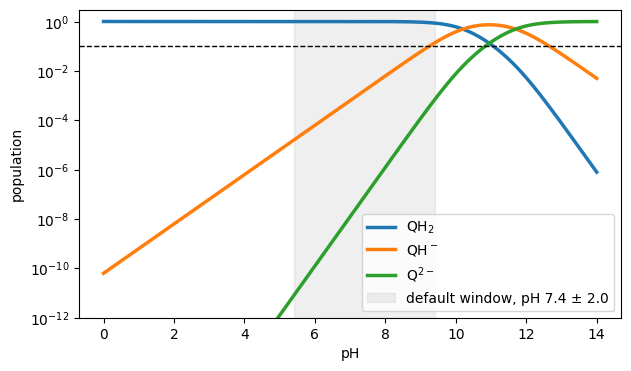

In [5]:
pH = np.linspace(0, 14, 1401)
X = populations(pH)
fig, ax = plt.subplots(figsize=(7, 4))
for row, lab in zip(X, ("QH$_2$", "QH$^-$", "Q$^{2-}$")):
    ax.semilogy(pH, np.where(row > 1e-13, row, np.nan), lw=2.5, label=lab)
ax.axvspan(5.4, 9.4, alpha=0.12, color="grey", label="default window, pH 7.4 ± 2.0")
ax.axhline(0.1, ls="--", color="k", lw=1)
ax.set_ylim(1e-12, 3); ax.set_xlabel("pH"); ax.set_ylabel("population")
ax.legend(); plt.show()

## 3 · E(pH) line, $E^\infty$ and cycle closure

$E(\mathrm{pH}) = E^\circ - k\,\mathrm{pH} + \tfrac{k}{2}\log_{10} D$ with $k = RT\ln 10/F$. At high pH it tends to $E^\infty = E^\circ - \tfrac{k}{2}(\mathrm{p}K_{\mathrm{a}1} + \mathrm{p}K_{\mathrm{a}2})$.

E_inf = 0.052 V vs SHE
slope between pH 2 and 4: -59.2 mV per pH unit
slope between pH 10.8 and 11.1: -29.6 mV per pH unit
slope between pH 13 and 14: -0.6 mV per pH unit


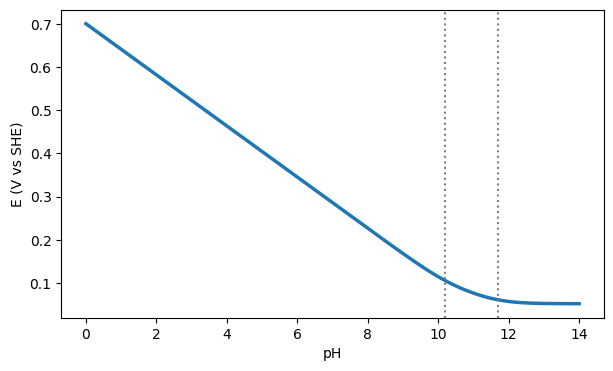

In [6]:
def potential(pH, e0=E0, pka1=PKA1, pka2=PKA2):
    d = 1 + 10.0 ** (pH - pka1) + 10.0 ** (2 * pH - pka1 - pka2)
    return e0 - K * pH + 0.5 * K * np.log10(d)

E_inf = E0 - 0.5 * K * (PKA1 + PKA2)
print(f"E_inf = {E_inf:.3f} V vs SHE")
for a, b in ((2, 4), (10.8, 11.1), (13, 14)):
    print(f"slope between pH {a} and {b}: {1000 * (potential(b) - potential(a)) / (b - a):.1f} mV per pH unit")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pH, potential(pH), lw=2.5)
for x in (PKA1, PKA2):
    ax.axvline(x, ls=":", color="grey")
ax.set_xlabel("pH"); ax.set_ylabel("E (V vs SHE)"); plt.show()

### Closure from a table of Gibbs energies

If $\mathrm{p}K_\mathrm{a}$, $E^\circ$ and $E^\infty$ are computed from one table of Gibbs energies, $E^\infty = E^\circ - \tfrac{RT\ln10}{2F}(\mathrm{p}K_{\mathrm{a}1}+\mathrm{p}K_{\mathrm{a}2})$ holds to rounding error, whatever the values of $G(\mathrm{H^+})$ and $E_\mathrm{SHE}$. The Gibbs energies below are chosen for illustration; in Session 3 you replace them by your Jaguar results.

In [7]:
G = {"Q": 0.0, "QH2": -770.0, "QHm": -486.5, "Q2m": -200.5}   # kcal/mol relative to Q, chosen for illustration
G_H = -270.3          # G*(H+, aq) at 1 M, kcal/mol (Kelly, Cramer and Truhlar 2006)
E_SHE = 4.28          # absolute SHE potential consistent with G_H (Isse and Gennaro 2010)

pka1 = (G["QHm"] + G_H - G["QH2"]) / RT_LN10
pka2 = (G["Q2m"] + G_H - G["QHm"]) / RT_LN10
e0 = -(G["QH2"] - G["Q"] - 2 * G_H) / (2 * F) - E_SHE
e_inf = -(G["Q2m"] - G["Q"]) / (2 * F) - E_SHE
residual = e_inf - (e0 - RT_LN10 / (2 * F) * (pka1 + pka2))
print(f"pKa1 {pka1:.2f}  pKa2 {pka2:.2f}  E° {e0:.3f} V  E_inf {e_inf:.3f} V  residual {residual:.1e} V")

pKa1 9.68  pKa2 11.51  E° 0.694 V  E_inf 0.067 V  residual 1.4e-15 V


## 4 · Micro- and macro-$\mathrm{p}K_\mathrm{a}$

For a first deprotonation that can occur at several sites, the macroscopic constant is the sum of the microscopic ones: $\mathrm{p}K^\mathrm{macro} = -\log_{10}\sum_i 10^{-\mathrm{p}K_i}$. For the second step the reciprocals add.

In [8]:
def macro_first(micro):
    return -np.log10(np.sum(10.0 ** (-np.asarray(micro))))

def macro_second(micro):
    return np.log10(np.sum(10.0 ** np.asarray(micro)))

print(f"two equivalent sites at 9.0: macro pKa1 = {macro_first([9.0, 9.0]):.2f}")
print(f"second step, two equivalent sites at 11.0: macro pKa2 = {macro_second([11.0, 11.0]):.2f}")
print(f"two different sites, 9.6 and 10.4 (illustrative): macro pKa1 = {macro_first([9.6, 10.4]):.2f}")

two equivalent sites at 9.0: macro pKa1 = 8.70
second step, two equivalent sites at 11.0: macro pKa2 = 11.30
two different sites, 9.6 and 10.4 (illustrative): macro pKa1 = 9.54


## 5 · From an error in $\Delta G$ to an error in $\mathrm{p}K_\mathrm{a}$ and $E$

$\delta\mathrm{p}K_\mathrm{a} = \delta\Delta G/(RT\ln10)$ and $|\delta E| = \delta\Delta G/(zF)$.

In [9]:
for dG in (0.5, 1.0, 2.0, 3.0):
    print(f"{dG:3.1f} kcal/mol -> {dG / RT_LN10:4.2f} pKa units, "
          f"{1000 * dG / F:5.1f} mV (1 e-), {1000 * dG / (2 * F):5.1f} mV (2 e-)")

0.5 kcal/mol -> 0.37 pKa units,  21.7 mV (1 e-),  10.8 mV (2 e-)
1.0 kcal/mol -> 0.73 pKa units,  43.4 mV (1 e-),  21.7 mV (2 e-)
2.0 kcal/mol -> 1.47 pKa units,  86.7 mV (1 e-),  43.4 mV (2 e-)
3.0 kcal/mol -> 2.20 pKa units, 130.1 mV (1 e-),  65.0 mV (2 e-)


## Exercises

1. Change `PKA1` and `PKA2` to 9.9 and 11.4 (another literature compilation). How much do $E^\infty$ and the populations at pH 9 change?
2. Under each reading of section 2, which single pH window keeps $\mathrm{QH_2}$, $\mathrm{QH^-}$ and $\mathrm{Q^{2-}}$?
3. Add the states of phenazine to the table in section 1 (homework) and check their charges and electron counts.